In [11]:
# ==========================================
# 1. Environment Setup & Imports
# ==========================================
%load_ext autoreload
%autoreload 2

import sys
import os
import gc
from pathlib import Path
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Import Shared Utilities
# Robustly find analysis_utils.py whether running from Root or Subdir
current_dir = Path.cwd()
possible_paths = [
    current_dir,                                         # Case 1: CWD is Notebook Dir
    current_dir / "VisualScripts" / "ResultAnalysis",    # Case 2: CWD is Project Root
    Path(__file__).parent if '__file__' in locals() else current_dir # Case 3: Script execution
]

utils_path = None
for p in possible_paths:
    if (p / "analysis_utils.py").exists():
        utils_path = p
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        print(f"[INFO] Found analysis_utils in: {p}")
        break

if utils_path is None:
    print("[WARN] analysis_utils.py not found in common paths. Please ensure it is accessible.")

try:
    import analysis_utils as utils
    from analysis_utils import PROJECT_ROOT
    print(f"Project Root: {PROJECT_ROOT}")
except ImportError as e:
    raise ImportError(f"Failed to import analysis_utils: {e}. Check if the file exists in {possible_paths}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[INFO] Found analysis_utils in: d:\research\ai+MACERsimulation\MACNet-v1\VisualScripts\ResultAnalysis
Project Root: d:\research\ai+MACERsimulation\MACNet-v1


In [12]:
# ==========================================
# 2. Configuration
# ==========================================
# 本 notebook 同时支持 direct-SFR 与 signed-closure checkpoint。
EXP_PREFIX = "Exp1_Rh12x20_FiveRuns_Closure_BestTrial23"
DATA_PREFIX = "Exp1_Rh12x20_FiveRuns_Closure_"
PROCESSED_RESOLUTION = "coarse_rh_12x20_sfr_v6"
MODEL_PATH_OVERRIDE = None

# 用 train/val/test cache 的并集重建唯一 snapshot 时间历史；不再为此读取数万个 HDF5。
BUILD_CACHED_HISTORY = True
# 仅用于核对 cache 与 processed HDF5 是否一致；日常分析应保持关闭。
ANALYZE_FULL_PROCESSED_RUNS = False
INFERENCE_BATCH_SIZE = 512

RESULTS_DIR = PROJECT_ROOT / "Results"
CACHE_DIR = PROJECT_ROOT / ".cache"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FIG_DIR_NAME = "figures_cached_history"
print(f"Using device: {DEVICE}")


Using device: cuda


In [7]:
# ==========================================
# 3. Load Contract, Cached Data & Model
# ==========================================
splits = ["train", "val", "test"]
datasets = {}
print("Loading cached datasets...")
for split in splits:
    pt_path = CACHE_DIR / f"{DATA_PREFIX}{split}.pt"
    if not pt_path.exists():
        raise FileNotFoundError(f"Missing required cache split: {pt_path}")
    ds = utils.CachedPTDataset(pt_path)
    datasets[split] = ds
    print(
        f"  - [{split.upper()}] n={len(ds)}, shape={tuple(ds.x.shape)}, "
        f"objective={ds.objective_mode}, conditioning={ds.conditioning_variable}"
    )

norm_stats = utils.load_norm_stats(CACHE_DIR / f"{DATA_PREFIX}norm.npz")
cache_metadata = utils.load_cache_metadata(CACHE_DIR / f"{DATA_PREFIX}train.pt")

model_path = (
    Path(MODEL_PATH_OVERRIDE)
    if MODEL_PATH_OVERRIDE
    else utils.find_latest_model(RESULTS_DIR, EXP_PREFIX)
)
if not model_path:
    raise RuntimeError(f"No model found for prefix {EXP_PREFIX!r}")

print(f"Target model: {model_path}")
model, model_type = utils.load_analysis_model(model_path, DEVICE, datasets)
print(f"Model type: {model_type}")
print(f"Objective: {model.objective_mode}")
if model.objective_mode == "signed_closure":
    print(f"Closure contract: {model.closure_transform}, scale={model.closure_scale}")

output_dir = model_path.parent
fig_dir = output_dir / FIG_DIR_NAME
fig_dir.mkdir(parents=True, exist_ok=True)
data_save_dir = output_dir / "prediction_data"
data_save_dir.mkdir(parents=True, exist_ok=True)


Loading cached datasets...
  - [TRAIN] n=26445, shape=(26445, 12, 12, 20), objective=signed_closure, conditioning=none
  - [VAL] n=5251, shape=(5251, 12, 12, 20), objective=signed_closure, conditioning=none
  - [TEST] n=5257, shape=(5257, 12, 12, 20), objective=signed_closure, conditioning=none
Target model: d:\research\ai+MACERsimulation\MACNet-v1\Results\Exp1_Rh12x20_FiveRuns_Closure_BestTrial23_20260912_131939\Exp1_Rh12x20_FiveRuns_Closure_BestTrial23_best_model.pth
Model type: convnet
Objective: signed_closure
Closure contract: signed_asinh, scale=93.18601400007357


In [13]:
# ==========================================
# 4. Predictions
# ==========================================
all_results = {}

def predict_cached_split(split, save_outputs=False):
    key = f"{split}_cached"
    ds = datasets[split]
    print(f"Predicting {key} ({len(ds)} cached rows)...")
    df = utils.predict_dataset(
        ds, model, DEVICE, model_type,
        batch_size=INFERENCE_BATCH_SIZE, return_feats=False
    )
    if "sample_uid" not in df.columns:
        raise RuntimeError(f"{key} 缺少 sample_uid，无法可靠合并并去重时间历史。")
    df["split"] = split
    all_results[key] = df
    if save_outputs:
        # 只保存预测与身份字段，不重复保存 cache 中已有的 x 和 latent。
        utils.save_to_h5(
            data_save_dir / f"{key}.h5", df, None, None, key
        )
        df.to_csv(output_dir / f"{key}_predictions.csv", index=False)
    gc.collect()
    return df

# test 是唯一用于报告无偏泛化指标的 split。
test_frame = predict_cached_split("test", save_outputs=True)

if BUILD_CACHED_HISTORY:
    # 合并三个 split 可覆盖预处理后保留的时间序列；train 中的 oversample
    # 会复制 snapshot，因此累计 SFR 前必须按 sample_uid 去重。
    cached_frames = [predict_cached_split("train"),
                     predict_cached_split("val"),
                     test_frame]
    full_cached = pd.concat(cached_frames, ignore_index=True)
    full_cached.attrs.update(test_frame.attrs)
    duplicate_count = int(full_cached.duplicated("sample_uid").sum())
    full_cached = (
        full_cached.drop_duplicates("sample_uid", keep="first")
        .sort_values(["type", "time", "sample_uid"])
        .reset_index(drop=True)
    )
    full_cached.attrs.update(test_frame.attrs)
    all_results["full_cached_history"] = full_cached
    full_cached.to_csv(
        output_dir / "full_cached_history_predictions.csv", index=False
    )
    utils.save_to_h5(
        data_save_dir / "full_cached_history.h5",
        full_cached, None, None, "full_cached_history"
    )
    print(
        f"Cached history: removed {duplicate_count} oversample duplicates; "
        f"kept {len(full_cached)} unique snapshots."
    )

# 完整 processed run 主要用于连续时间历史；默认关闭，避免把它误当成独立 test。
if ANALYZE_FULL_PROCESSED_RUNS:
    raw_frames = []
    for group_name in cache_metadata.get("available_groups", []):
        folder = PROJECT_ROOT / "data" / group_name / PROCESSED_RESOLUTION
        if not folder.exists():
            print(f"[WARN] Missing processed group: {folder}")
            continue
        ds_full = utils.HDF5Dataset(
            (str(folder), 0),
            mean=norm_stats["mean"],
            std=norm_stats["std"],
            reference_dataset=datasets["train"],
            exclude_raw_snapshot_indices=(0,),
        )
        print(f"  > {group_name}: {len(ds_full)} snapshots")
        frame, feats, x_data = utils.predict_dataset(
            ds_full, model, DEVICE, model_type,
            batch_size=INFERENCE_BATCH_SIZE, return_feats=True
        )
        frame["type"] = group_name
        utils.save_to_h5(
            data_save_dir / f"full_{group_name}.h5",
            frame, feats, x_data, group_name
        )
        raw_frames.append(frame)
        del feats, x_data
        gc.collect()
    if raw_frames:
        full = pd.concat(raw_frames, ignore_index=True)
        full.attrs.update(raw_frames[0].attrs)
        all_results["full_processed"] = full
        full.to_csv(output_dir / "full_processed_predictions.csv", index=False)


Predicting test_cached (5257 cached rows)...
Predicting train_cached (26445 cached rows)...
Predicting val_cached (5251 cached rows)...
Cached history: removed 10686 oversample duplicates; kept 26267 unique snapshots.


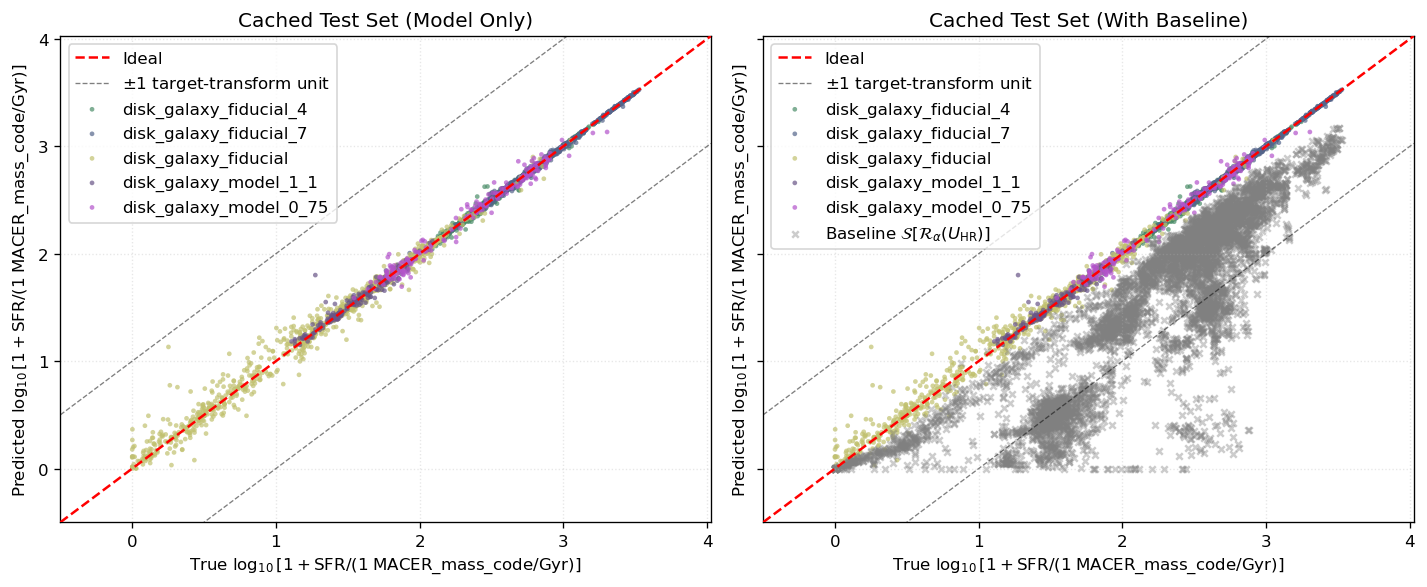

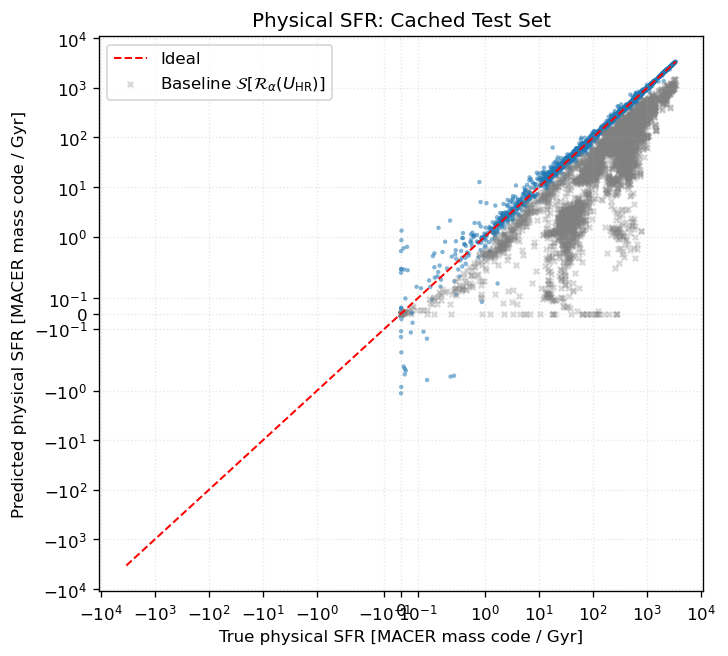

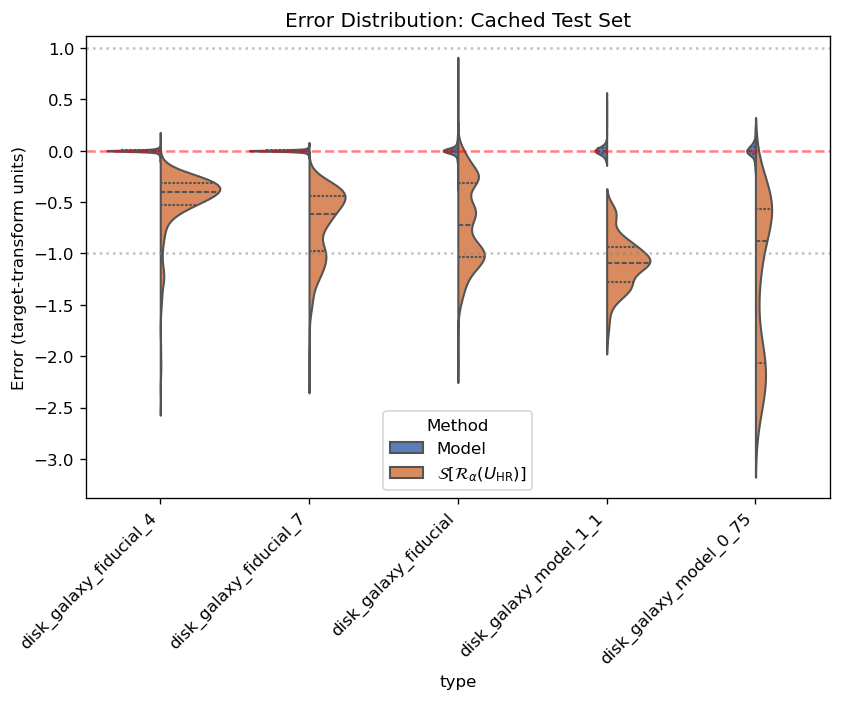

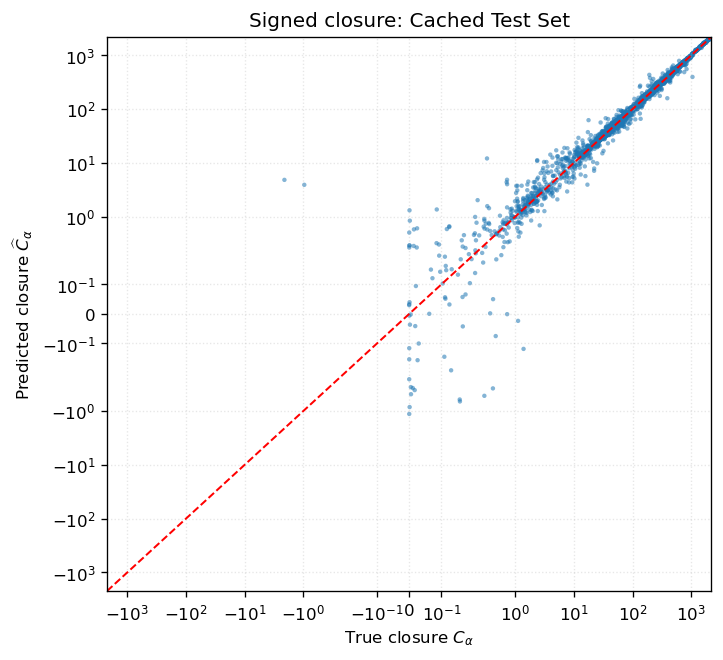

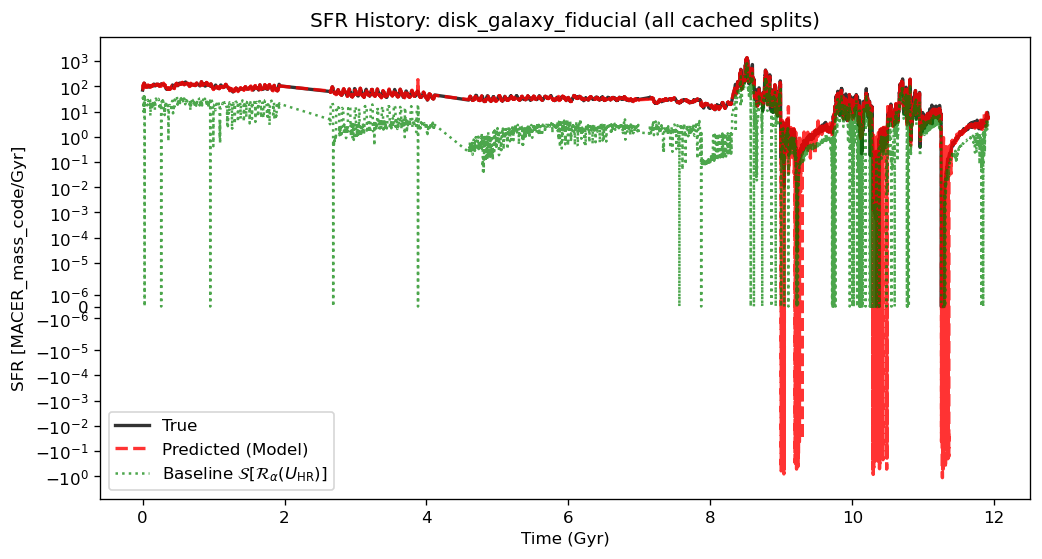

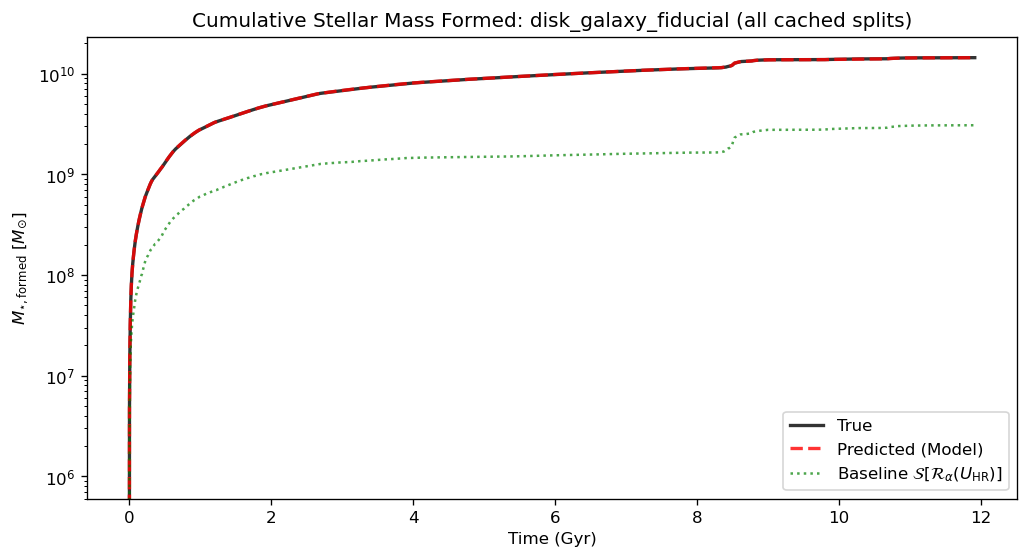

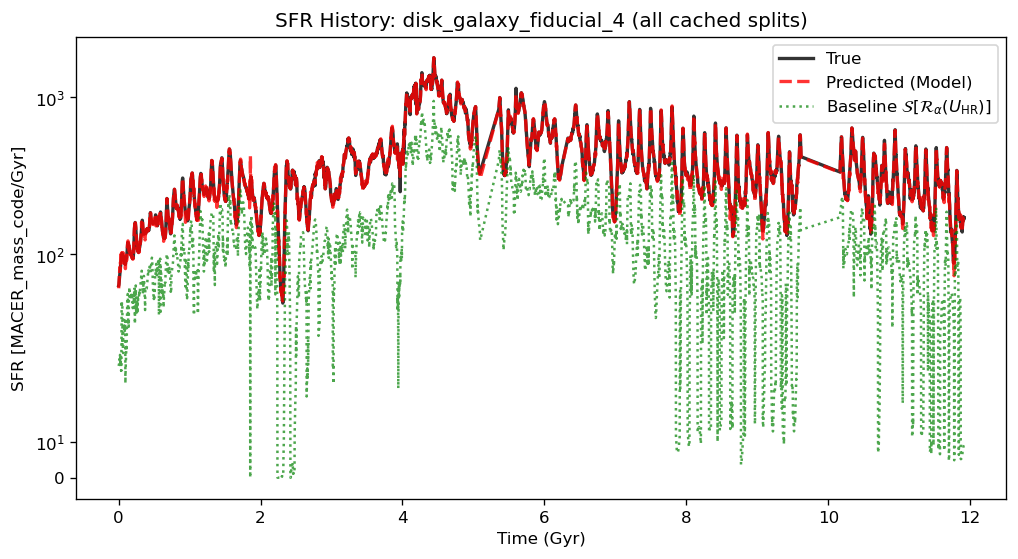

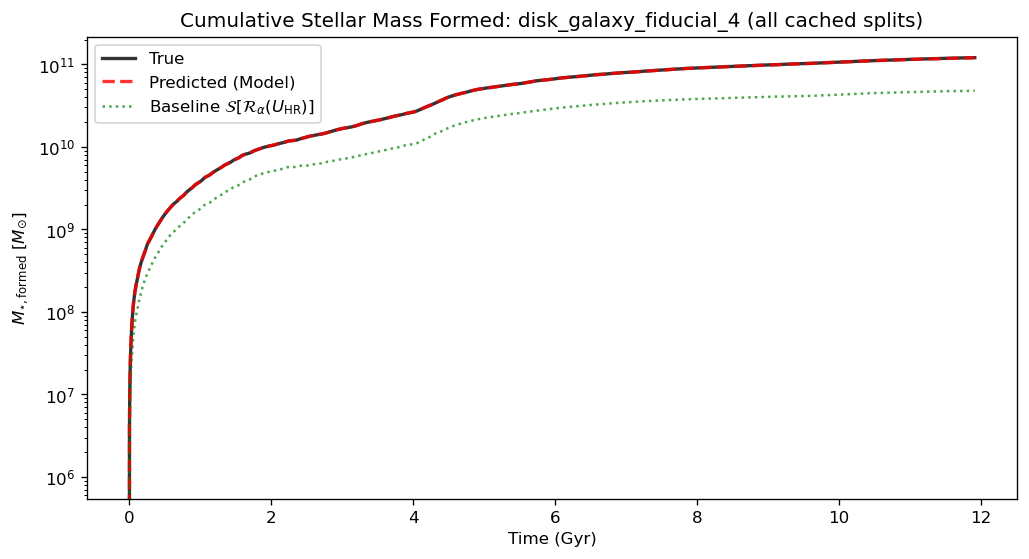

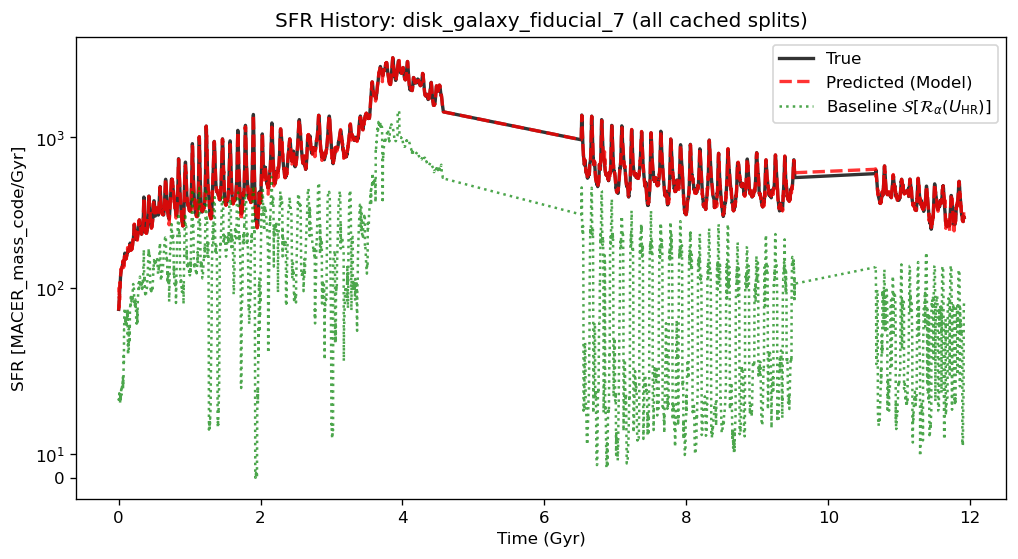

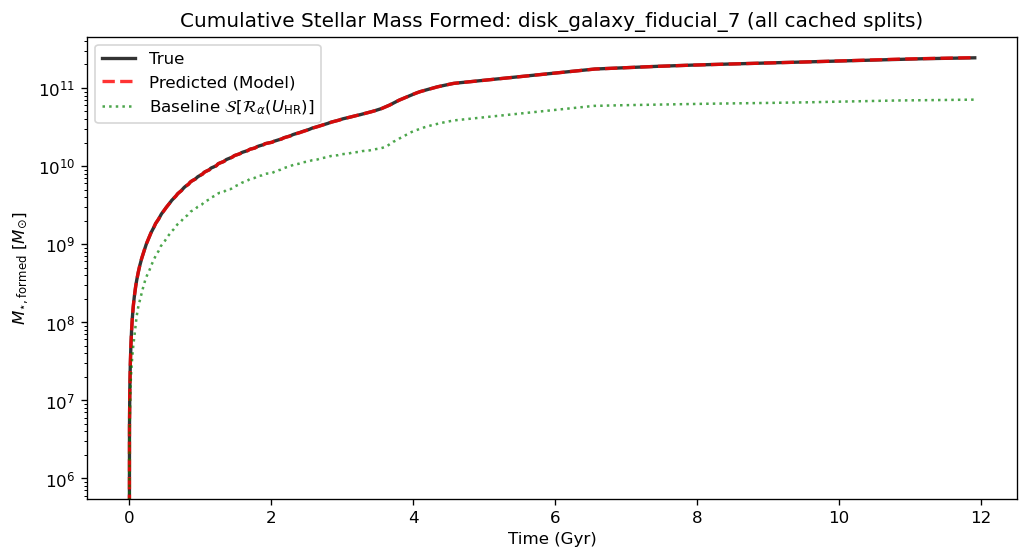

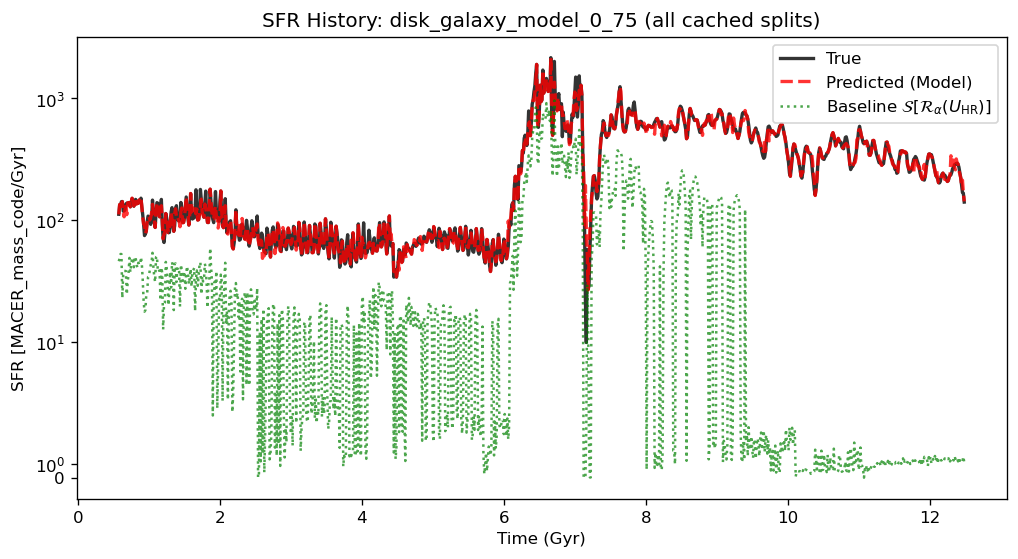

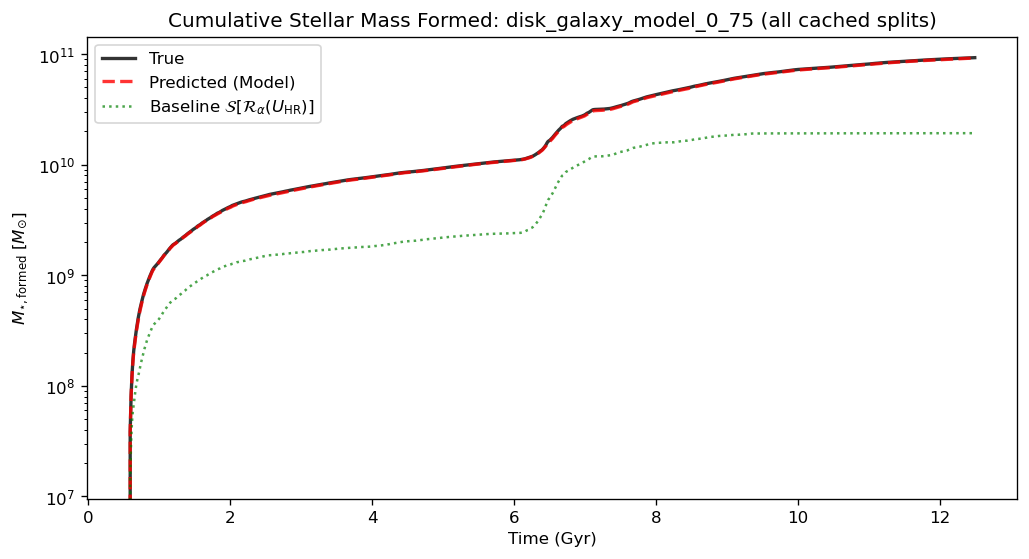

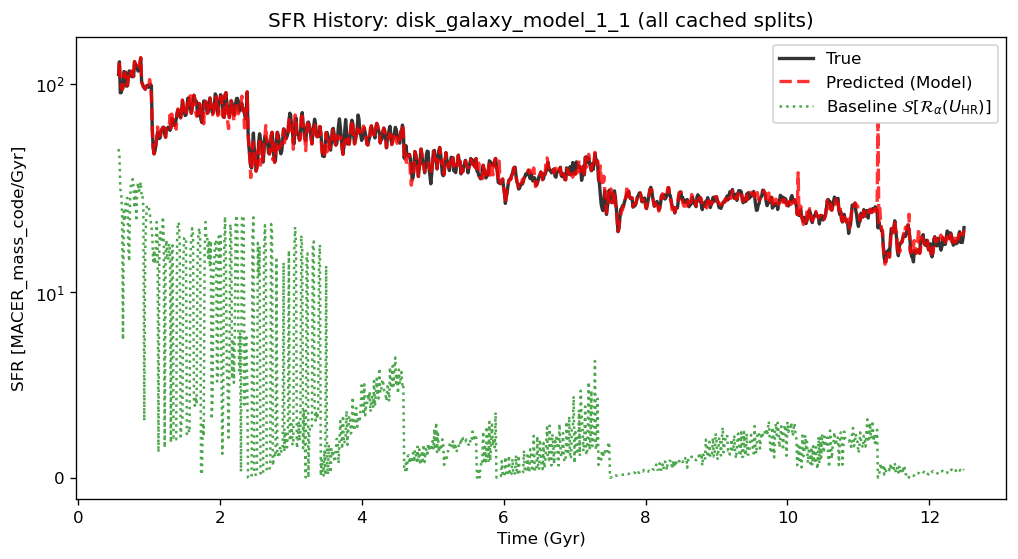

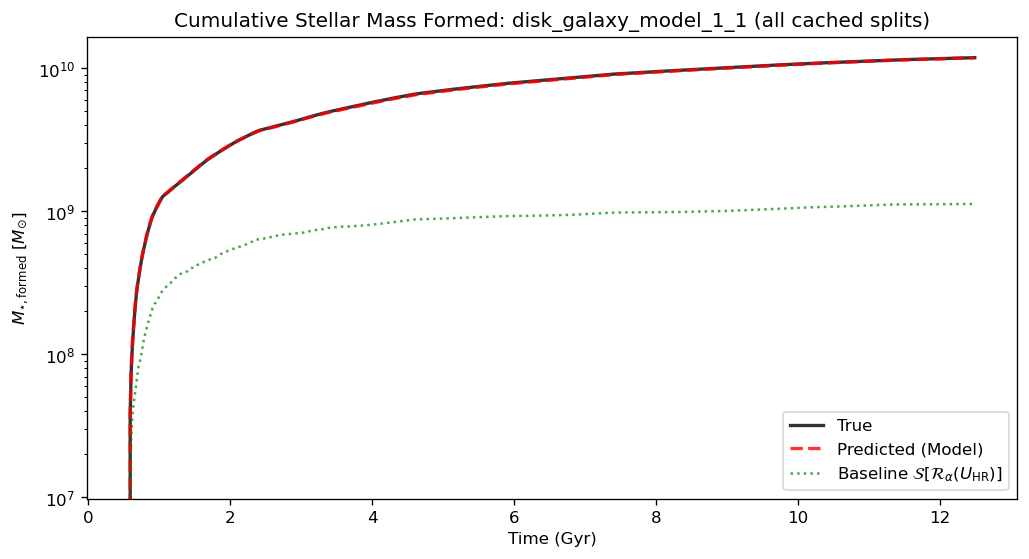

,Dataset,Physical_RMSE,Physical_MAE,Physical_R2,MedianAbsRelativeError_nonzero,NegativePredFrac,N_valid,RMSE,MAE,R2,OutlierFrac (|target error|>1)
0,Cached Test Set: Model,19.364,7.6958,0.99819,0.01817,0.003424,5257,NaN,NaN,NaN,NaN
1,Cached Test Set: Model (target space),NaN,NaN,NaN,NaN,NaN,5239,0.042173,0.019201,0.9962,0
2,Cached Test Set: MACER-LR baseline,393.81,249.07,0.25321,0.72803,0,5257,NaN,NaN,NaN,NaN
3,Cached Test Set: KS baseline,578.02,358.06,-0.60883,0.99125,0,5257,NaN,NaN,NaN,NaN


In [14]:
# ==========================================
# 5. Metrics & Visualizations
# ==========================================
metrics_list = []

def analyze_frame(df, label):
    # 最终判断以物理 SFR 空间为主，同时保留目标变换空间指标。
    metrics_list.append(utils.get_physical_sfr_metrics(df, "sfr_pred", f"{label}: Model"))
    metrics_list.append(utils.get_metrics_summary(df["y_true"], df["y_pred"], f"{label}: Model (target space)"))

    if "sfr_macer_baseline" in df.columns:
        metrics_list.append(
            utils.get_physical_sfr_metrics(
                df, "sfr_macer_baseline", f"{label}: MACER-LR baseline"
            )
        )
    if "sfr_ks_baseline" in df.columns:
        metrics_list.append(
            utils.get_physical_sfr_metrics(
                df, "sfr_ks_baseline", f"{label}: KS baseline"
            )
        )

    utils.plot_scatter(df, label, fig_dir)
    utils.plot_physical_sfr_scatter(df, label, fig_dir)
    utils.plot_error_dist(df, label, fig_dir)
    utils.plot_closure_scatter(df, label, fig_dir)

analyze_frame(all_results["test_cached"], "Cached Test Set")

# 完整时间历史混合 train/val/test，只用于演化可视化；不能报告为 test 指标。
if "full_cached_history" in all_results:
    df_history = all_results["full_cached_history"]
    for group_name, sub in df_history.groupby("type", sort=True):
        sub = sub.sort_values(["time", "sample_uid"])
        utils.plot_sfr_history(sub, f"{group_name} (all cached splits)", fig_dir)
        utils.plot_cumulative_sfr(sub, f"{group_name} (all cached splits)", fig_dir)

# 可选的 processed-HDF5 路径仅作一致性核对，默认不执行。
if "full_processed" in all_results:
    df_full = all_results["full_processed"]
    for group_name, sub in df_full.groupby("type", sort=True):
        utils.plot_sfr_history(sub, group_name, fig_dir)
        utils.plot_cumulative_sfr(sub, group_name, fig_dir)

metrics_df = pd.DataFrame(metrics_list)
pd.options.display.float_format = "{:,.5g}".format
display(metrics_df)
metrics_df.to_csv(output_dir / "summary_metrics.csv", index=False)


In [15]:
# ==========================================
# 6. Save Markdown Report
# ==========================================
md_path = output_dir / "summary_metrics.md"
with open(md_path, "w", encoding="utf-8") as f:
    f.write(f"# Analysis Results: {EXP_PREFIX}\n\n")
    f.write(f"- **Model**: `{model_path.name}`\n")
    f.write(f"- **Model type**: `{model_type}`\n")
    f.write(f"- **Objective**: `{model.objective_mode}`\n")
    f.write(f"- **Data cache**: `{DATA_PREFIX}`\n")
    if "full_cached_history" in all_results:
        f.write(
            f"- **History source**: unique union of train/val/test cache "
            f"(`{len(all_results['full_cached_history'])}` snapshots); "
            "history plots are diagnostic and test metrics remain test-only.\n"
        )
    if model.objective_mode == "signed_closure":
        f.write(
            f"- **Closure transform**: `{model.closure_transform}` "
            f"with scale `{model.closure_scale}`\n"
        )
    f.write("\n## Metrics\n\n")
    f.write(metrics_df.to_markdown(index=False, floatfmt=".5g"))
    f.write("\n\n## Visualizations\n")
    for img in sorted(fig_dir.glob("*.png")):
        f.write(f"\n### {img.stem}\n\n![{img.stem}]({FIG_DIR_NAME}/{img.name})\n")

print(f"Saved report to {md_path}")


Saved report to d:\research\ai+MACERsimulation\MACNet-v1\Results\Exp1_Rh12x20_FiveRuns_Closure_BestTrial23_20260912_131939\summary_metrics.md
